### Experiment N0: 07

#### Import Libraries

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.width", 200)
%matplotlib inline

#### Load dataset

In [2]:
df = pd.read_csv("insurance.csv")
print("Shape:", df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


#### Explore and clean the dataset

In [3]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [4]:
df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (1337, 7)


#### Visualize The Data

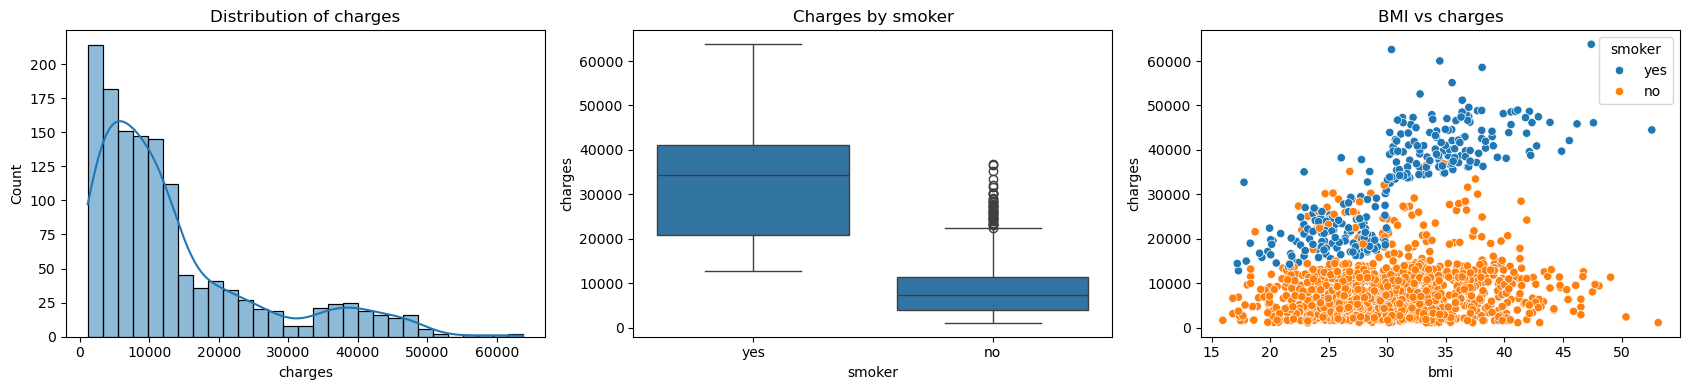

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df["charges"], kde=True, ax=ax[0]); ax[0].set_title("Distribution of charges")
sns.boxplot(x="smoker", y="charges", data=df, ax=ax[1]); ax[1].set_title("Charges by smoker")
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df, ax=ax[2]); ax[2].set_title("BMI vs charges")
plt.tight_layout(); plt.show()

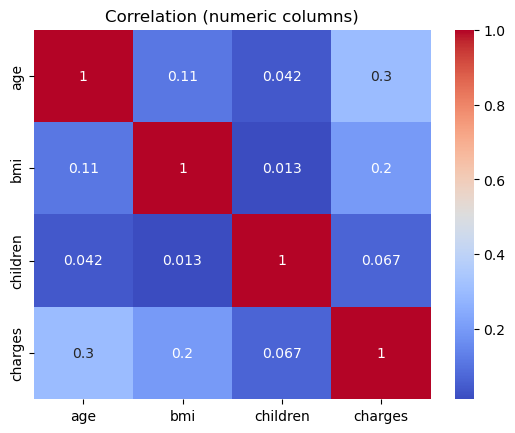

In [6]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation (numeric columns)"); plt.show()

#### Standardization and Encoding

In [7]:
TARGET = "charges"
X = df.drop(columns=[TARGET])
y = df[TARGET]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

def preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first"), cat_cols),
    ])

Numeric: ['age', 'bmi', 'children']
Categorical: ['sex', 'smoker', 'region']


#### Train-Test-Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1069, 6)  Test: (268, 6)


#### Create The Models

In [9]:
models = {
    "Linear Regression": make_pipeline(preprocessor(), LinearRegression()),
    "Polynomial (deg 2)": make_pipeline(preprocessor(), PolynomialFeatures(2), LinearRegression()),
    "Decision Tree (unpruned)": make_pipeline(preprocessor(), DecisionTreeRegressor(random_state=42)),
    "Random Forest": make_pipeline(preprocessor(), RandomForestRegressor(n_estimators=100, random_state=42)),
    "SVR (RBF)": make_pipeline(preprocessor(), SVR(kernel="rbf", C=y.max(), epsilon=y.std() * 0.1)),
}

#### Train and evaluate

In [10]:
rows, preds = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0

    p_train, p_test = model.predict(X_train), model.predict(X_test)
    preds[name] = p_test
    rows[name] = {
        "Train R2": r2_score(y_train, p_train),
        "Test R2": r2_score(y_test, p_test),
        "CV R2 (5-fold)": cross_val_score(model, X, y, cv=5, scoring="r2").mean(),
        "MAE": mean_absolute_error(y_test, p_test),
        "MSE": mean_squared_error(y_test, p_test),
        "RMSE": np.sqrt(mean_squared_error(y_test, p_test)),
        "Fit time (s)": fit_time,
    }

results = pd.DataFrame(rows).T.sort_values("Test R2", ascending=False).round(3)
results

,Train R2,Test R2,CV R2 (5-fold),MAE,MSE,RMSE,Fit time (s)
Polynomial (deg 2),0.834,0.883,0.835,2867.317,2.158584e+07,4646.057,0.052
Random Forest,0.974,0.878,0.837,2663.329,2.237258e+07,4729.966,0.711
SVR (RBF),0.861,0.878,0.837,2524.710,2.239995e+07,4732.859,0.604
Decision Tree (unpruned),1.000,0.810,0.698,2804.812,3.495303e+07,5912.109,0.021
Linear Regression,0.730,0.807,0.747,4177.046,3.547802e+07,5956.343,0.031


#### Visualize Comparison

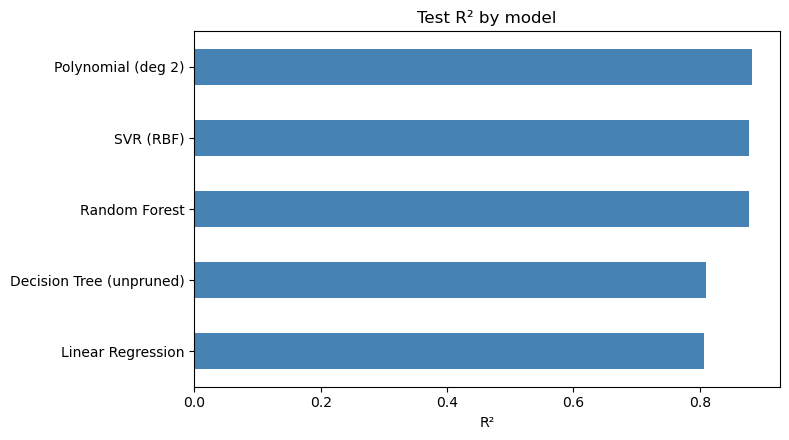

In [11]:
results["Test R2"].sort_values().plot(kind="barh", figsize=(8, 4.5), color="steelblue")
plt.title("Test R² by model"); plt.xlabel("R²"); plt.tight_layout(); plt.show()

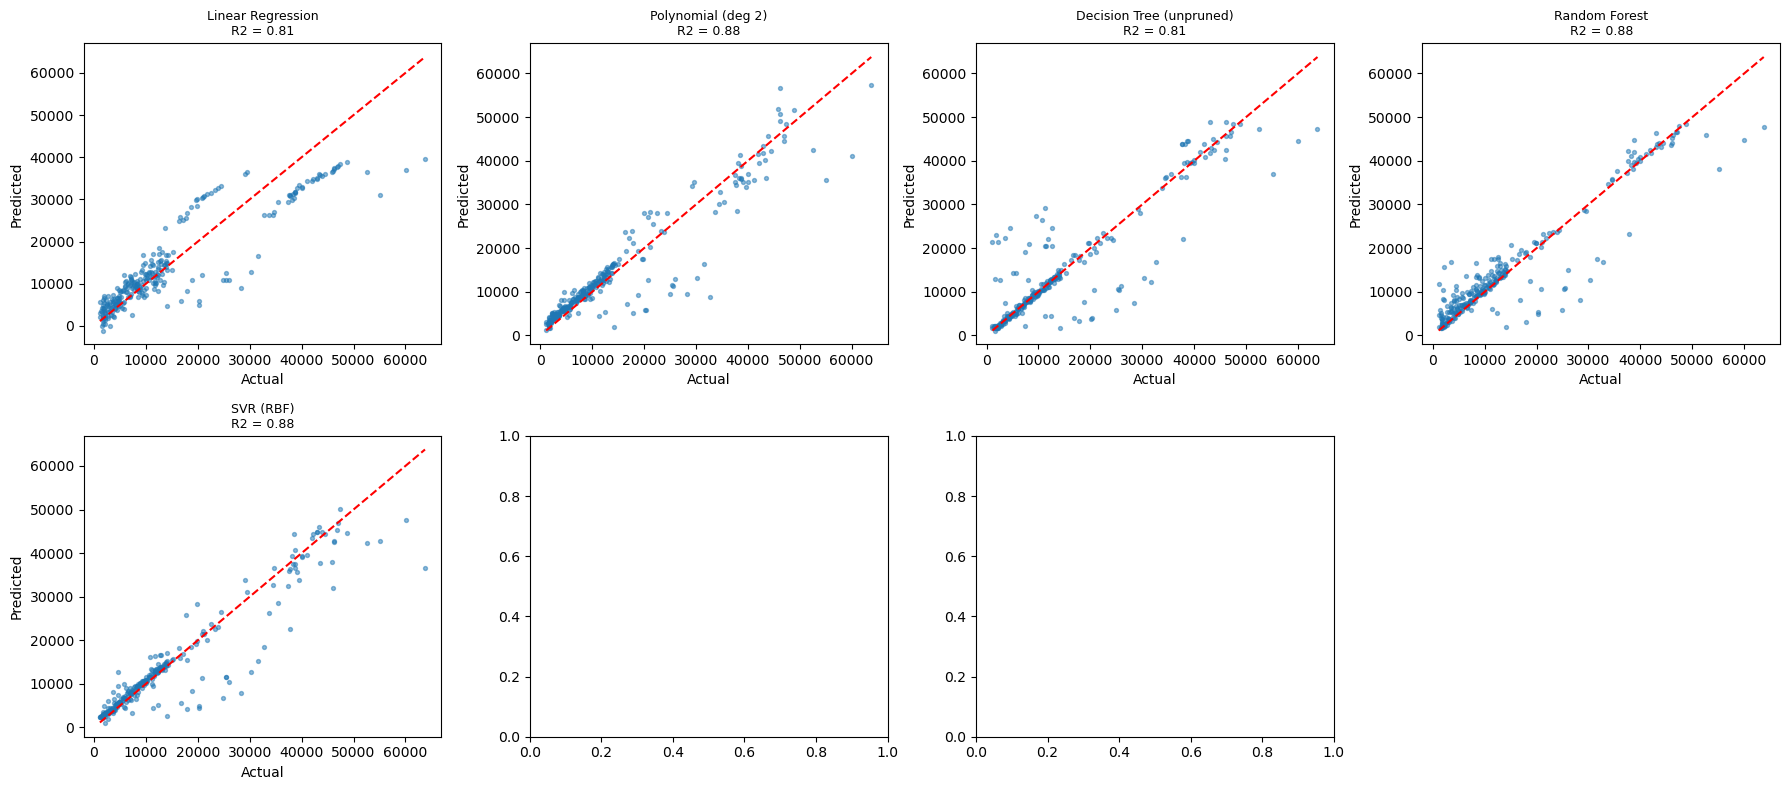

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test, p, s=8, alpha=0.5)
    lim = [y_test.min(), y_test.max()]
    ax.plot(lim, lim, "r--")
    ax.set_title(f"{name}\nR2 = {r2_score(y_test, p):.2f}", fontsize=9)
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

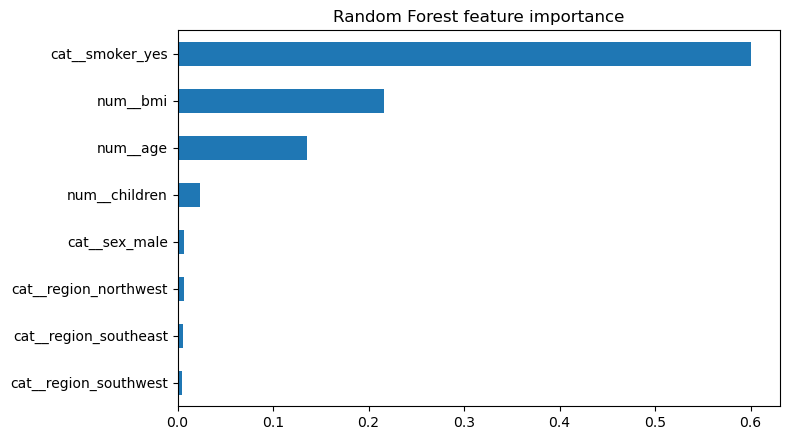

In [13]:
rf = models["Random Forest"]
names = rf[0].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names).sort_values()
imp.plot(kind="barh", figsize=(8, 4.5), title="Random Forest feature importance")
plt.tight_layout(); plt.show()

#### Best Model 

In [14]:
best = results.index[0]
print("Best model by Test R2:", best)
results.loc[[best]]

Best model by Test R2: Polynomial (deg 2)


,Train R2,Test R2,CV R2 (5-fold),MAE,MSE,RMSE,Fit time (s)
Polynomial (deg 2),0.834,0.883,0.835,2867.317,2.158584e+07,4646.057,0.052


#### Conclusion
##### Polynomial Regression (degree 2) achieved the highest Test R² (0.883) and the lowest RMSE (4646), while training about ten times faster than Random Forest and SVR. Random Forest and SVR performed almost equally (Test R² = 0.878, CV R² = 0.837), with SVR giving the lowest MAE. The Decision Tree overfitted strongly (Train R² = 1.0, CV R² = 0.698), and Linear Regression performed worst (MAE = 4177) because it cannot model the interaction between smoking status and BMI. Considering accuracy, generalization and efficiency together, Polynomial Regression is the most suitable model for this dataset, though Random Forest and SVR are close alternatives. The best algorithm depends on the data's characteristics, so no single model is superior in every case
